# Logistic Regression and Probabilistic Classification

> Model binary outcomes, examine probabilities, and understand decision thresholds.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Fit logistic regression for classification.
- Distinguish a probability estimate from a class decision.
- Inspect coefficients and use a confusion matrix.
- Learn why the default threshold of 0.5 is a convention, not a law.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score

X, y = load_breast_cancer(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= .5).astype(int)
print("ROC-AUC:", round(roc_auc_score(y_test, prob), 3))
print(classification_report(y_test, pred, zero_division=0))

ROC-AUC: 0.995
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



,threshold,precision,recall,f1
0,0.20,0.973,1.000,0.986
1,0.35,0.973,1.000,0.986
2,0.50,0.986,0.986,0.986
3,0.65,0.985,0.931,0.957
4,0.80,0.985,0.917,0.950


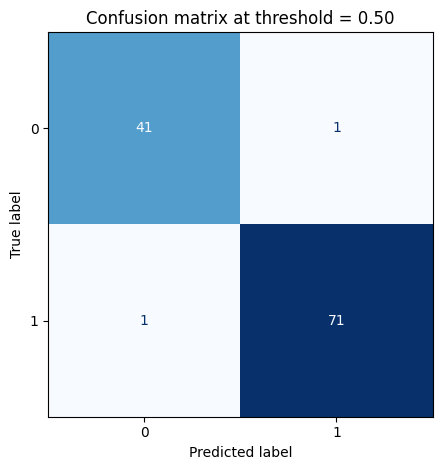

In [2]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues", colorbar=False)
plt.title("Confusion matrix at threshold = 0.50")
plt.tight_layout()

thresholds = np.array([.2, .35, .5, .65, .8])
rows = []
from sklearn.metrics import precision_score, recall_score, f1_score
for threshold in thresholds:
    p = (prob >= threshold).astype(int)
    rows.append({"threshold": threshold, "precision": precision_score(y_test, p, zero_division=0), "recall": recall_score(y_test, p, zero_division=0), "f1": f1_score(y_test, p, zero_division=0)})
display(pd.DataFrame(rows).round(3))

## Coefficients and probabilities
A positive logistic coefficient increases log-odds for the positive class when other features are held fixed. Coefficients are scale-dependent. The positive label meaning must be documented; scikit-learn's `classes_` reveals its class ordering.

In [3]:
clf = model.named_steps["logisticregression"]
coef_table = pd.DataFrame({"feature": X.columns, "coefficient_scaled": clf.coef_[0]}).assign(abs_coef=lambda d: d.coefficient_scaled.abs()).sort_values("abs_coef", ascending=False)
display(coef_table.head(8).drop(columns="abs_coef").round(3))
print("Class order:", clf.classes_)

Class order: [0 1]


,feature,coefficient_scaled
21,worst texture,-1.255
10,radius error,-1.083
27,worst concave points,-0.954
23,worst area,-0.948
20,worst radius,-0.948
28,worst symmetry,-0.939
13,area error,-0.929
26,worst concavity,-0.823


## Pitfalls
- Do not report an AUC from hard class labels; use continuous scores or probabilities.
- A high AUC does not guarantee calibrated probabilities.
- Threshold tuning belongs on validation data, not the final test set.
- On high-stakes tasks, inspect errors and group performance as well as aggregate metrics.

## Practice
Compare recall at thresholds 0.35 and 0.65. Which threshold would you choose if false negatives were more costly, and what other information would you need?